In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
results_df = pd.read_csv("../results/model_comparison.csv")

print("Model Comparison Results:")
display(results_df.round(4))

Model Comparison Results:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.7984,0.6552,0.5080,0.5723,0.8422
1,Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8418
2,Random Forest,0.7850,0.6179,0.4973,0.5511,0.8253
3,Decision Tree,0.8006,0.6667,0.4973,0.5697,0.8219


In [3]:
best_model = results_df.loc[
    results_df["ROC-AUC"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))
print("ROC-AUC:", round(best_model["ROC-AUC"], 4))

Best Model: Gradient Boosting
Accuracy: 0.7984
Precision: 0.6552
Recall: 0.508
F1 Score: 0.5723
ROC-AUC: 0.8422


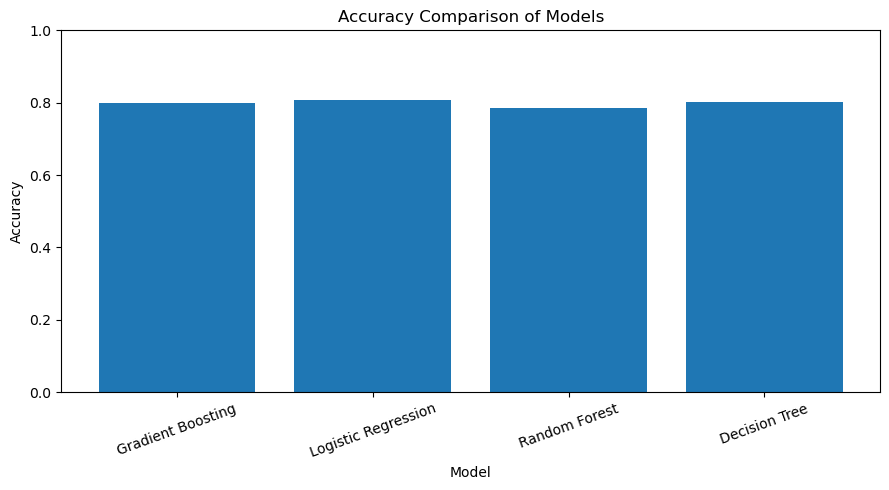

In [4]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.title("Accuracy Comparison of Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


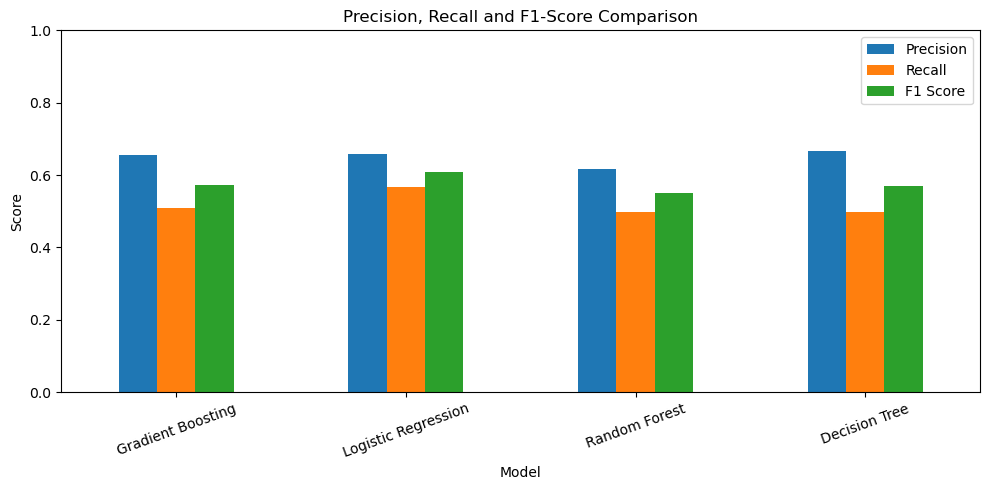

In [5]:
metrics = ["Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

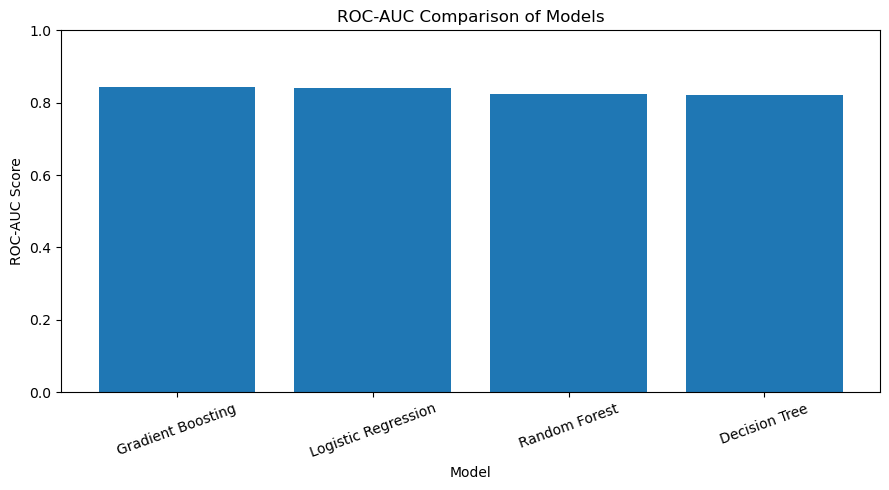

In [6]:
plt.figure(figsize=(9, 5))

plt.bar(results_df["Model"], results_df["ROC-AUC"])

plt.title("ROC-AUC Comparison of Models")
plt.xlabel("Model")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [9]:
predictions = pd.read_csv("../results/churn_predictions.csv")

print("Prediction Results:")
display(predictions.head())

Prediction Results:


,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.019736
1,0,1,0.806766
2,0,0,0.055371
3,0,0,0.352745
4,0,0,0.017915


In [8]:
print("Actual Churn Distribution:")
print(predictions["Actual_Churn"].value_counts())

Actual Churn Distribution:
Actual_Churn
0    1035
1     374
Name: count, dtype: int64


In [10]:
print("Predicted Churn Distribution:")
print(predictions["Predicted_Churn"].value_counts())

Predicted Churn Distribution:
Predicted_Churn
0    1119
1     290
Name: count, dtype: int64


In [11]:
## Count correct and incorrect predictions

In [12]:
correct = (
    predictions["Actual_Churn"]
    == predictions["Predicted_Churn"]
).sum()

incorrect = (
    predictions["Actual_Churn"]
    != predictions["Predicted_Churn"]
).sum()

print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Total Predictions:", len(predictions))

Correct Predictions: 1125
Incorrect Predictions: 284
Total Predictions: 1409


In [13]:
results_df.to_csv(
    "../results/model_evaluation_summary.csv",
    index=False
)